# US Baby Name

## GIỚI THIỆU
Dữ Liệu `US_BaBy_Names.csv` chứa thông tin của các em bé sinh từ 2004 - 2014 tại Mỹ. Dựa vào tập dữ liệu trên, bạn hãy thực hiện các bài tập sau:

## TÌM HIỂU DỮ LIỆU

### 01. Đọc dữ liệu

In [20]:
import pandas as pd
import numpy as np

In [21]:
df = pd.read_csv('C:/Users/mythi/Desktop/tailieu/HK1(2026-2027)/TKMT/data/US_Baby_Names.csv', header=0)

### 02. Hiển thị 10 dòng dữ liệu bất kỳ

In [22]:
df.head(10)

,Unnamed: 0,Id,Name,Year,Gender,State,Count
0,11349,11350,Emma,2004,F,AK,62
1,11350,11351,Madison,2004,F,AK,48
2,11351,11352,Hannah,2004,F,AK,46
3,11352,11353,Grace,2004,F,AK,44
4,11353,11354,Emily,2004,F,AK,41
5,11354,11355,Abigail,2004,F,AK,37
6,11355,11356,Olivia,2004,F,AK,33
7,11356,11357,Isabella,2004,F,AK,30
8,11357,11358,Alyssa,2004,F,AK,29
9,11358,11359,Sophia,2004,F,AK,28


In [26]:
df.sample(10)

,Unnamed: 0,Id,Name,Year,Gender,State,Count
75649,533712,533713,Hailie,2007,F,CA,33
848113,4900148,4900149,Paxton,2004,F,TX,9
596970,3403101,3403102,Malaysia,2005,F,NJ,5
923986,5152412,5152413,Edgar,2005,M,UT,28
543567,3096571,3096572,Kristian,2004,F,NC,7
130941,702118,702119,Ares,2012,M,CA,46
138422,709599,709600,Zacharias,2014,M,CA,7
568804,3181571,3181572,Casey,2011,M,NC,19
572479,3185246,3185247,Neymar,2014,M,NC,30
420278,2311082,2311083,Koby,2008,M,MA,9


### 03. Cho biết kích thước dữ liệu

In [27]:
df.shape

(1016395, 7)

### 04. Xóa 2 cột 'Unnamed: 0' and 'Id'

In [31]:
df = df.drop(columns=['Unnamed: 0','Id'])

In [32]:
df.head(10)

,Name,Year,Gender,State,Count
0,Emma,2004,F,AK,62
1,Madison,2004,F,AK,48
2,Hannah,2004,F,AK,46
3,Grace,2004,F,AK,44
4,Emily,2004,F,AK,41
5,Abigail,2004,F,AK,37
6,Olivia,2004,F,AK,33
7,Isabella,2004,F,AK,30
8,Alyssa,2004,F,AK,29
9,Sophia,2004,F,AK,28


### 05. Cho biết số lượng bé trai, bé gái?

In [33]:
df['Gender'].value_counts()

Gender
F    558846
M    457549
Name: count, dtype: int64

### 06. Trong bộ dữ liệu có bao nhiêu tên khác nhau?

In [34]:
df['Name'].nunique()

17632

In [35]:
df['Name'].value_counts()

Name
Riley      1112
Avery      1080
Jordan     1073
Peyton     1064
Hayden     1049
           ... 
Kong          1
Adrion        1
Braun         1
Evrett        1
Coalton       1
Name: count, Length: 17632, dtype: int64

### 07. Tên nào xuất hiện ít nhất?

In [36]:
df['Name'].value_counts().tail()

Name
Kong       1
Adrion     1
Braun      1
Evrett     1
Coalton    1
Name: count, dtype: int64

### 08. Top 10 tên được sử dụng nhiều nhất?

In [16]:
df['Name'].value_counts().head(10)

Name
Riley     1112
Avery     1080
Jordan    1073
Peyton    1064
Hayden    1049
Taylor    1033
Jayden    1031
Alexis     984
Payton     971
Angel      962
Name: count, dtype: int64

## TRỰC QUAN DỮ LIỆU

### 09. Vẽ đồ thị top 10 tên xuất hiện nhiều nhất năm 2014

In [37]:
import matplotlib.pyplot as plt

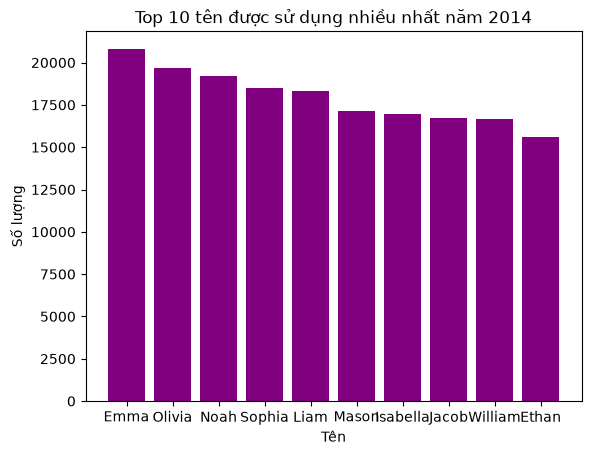

In [40]:

# Lấy dữ liệu năm 2014
data = df[df['Year'] == 2014]

# Tính tổng số lượng theo tên
data = data.groupby('Name')['Count'].sum()

# Sắp xếp từ lớn đến nhỏ và lấy 10 tên đầu
data = data.sort_values(ascending=False).head(10)

# Vẽ biểu đồ
plt.bar(data.index,data.values, color='purple')

plt.title('Top 10 tên được sử dụng nhiều nhất năm 2014')
plt.xlabel('Tên')
plt.ylabel('Số lượng')
plt.show()

### 10. Vẽ đồ thị thể hiện tỷ lệ nam nữ qua các năm 2004-2014

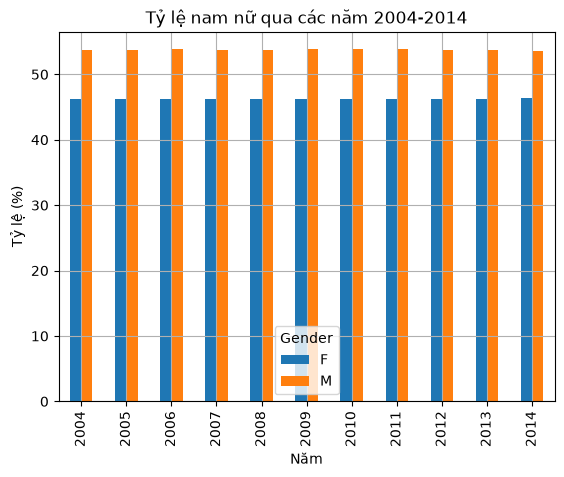

In [46]:

# Lấy dữ liệu từ năm 2004 đến 2014
data = df[(df['Year'] >= 2004) & (df['Year'] <= 2014)]

# Tính tổng số bé trai và bé gái theo từng năm
gender = data.groupby(['Year', 'Gender'])['Count'].sum().unstack()

# Tính tỷ lệ nam và nữ (%)
gender_percent = gender.div(gender.sum(axis=1), axis=0) * 100

# Vẽ biểu đồ
gender_percent.plot(kind='bar')

plt.title('Tỷ lệ nam nữ qua các năm 2004-2014')
plt.xlabel('Năm')
plt.ylabel('Tỷ lệ (%)')

plt.grid()
plt.show()